In [1]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
df = pd.read_csv(BASE_DIR / "titanic.csv")
print(df.head())
print(df.shape)
df.info()
print(df.isna().sum())
print(df[["sex", "class", "survived", "sibsp", "age", "fare"]].nunique())
print(df[["age", "fare", "sibsp", "parch"]].describe())

class_order = ["Third", "Second", "First"]
df["class"] = pd.Categorical(df["class"], categories=class_order, ordered=True)
df["survival"] = df["survived"].map({0: "Did not survive", 1: "Survived"})
age_data = df.dropna(subset=["age"])
print(age_data.shape)
print(df["survival"].value_counts())
print(df["survival"].value_counts(normalize=True).mul(100).round(1))
sns.set_theme(style="whitegrid", context="talk")



   survived  pclass     sex   age  ...  deck  embark_town  alive  alone
0         0       3    male  22.0  ...   NaN  Southampton     no  False
1         1       1  female  38.0  ...     C    Cherbourg    yes  False
2         1       3  female  26.0  ...   NaN  Southampton    yes   True
3         1       1  female  35.0  ...     C  Southampton    yes  False
4         0       3    male  35.0  ...   NaN  Southampton     no   True

[5 rows x 15 columns]
(891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class

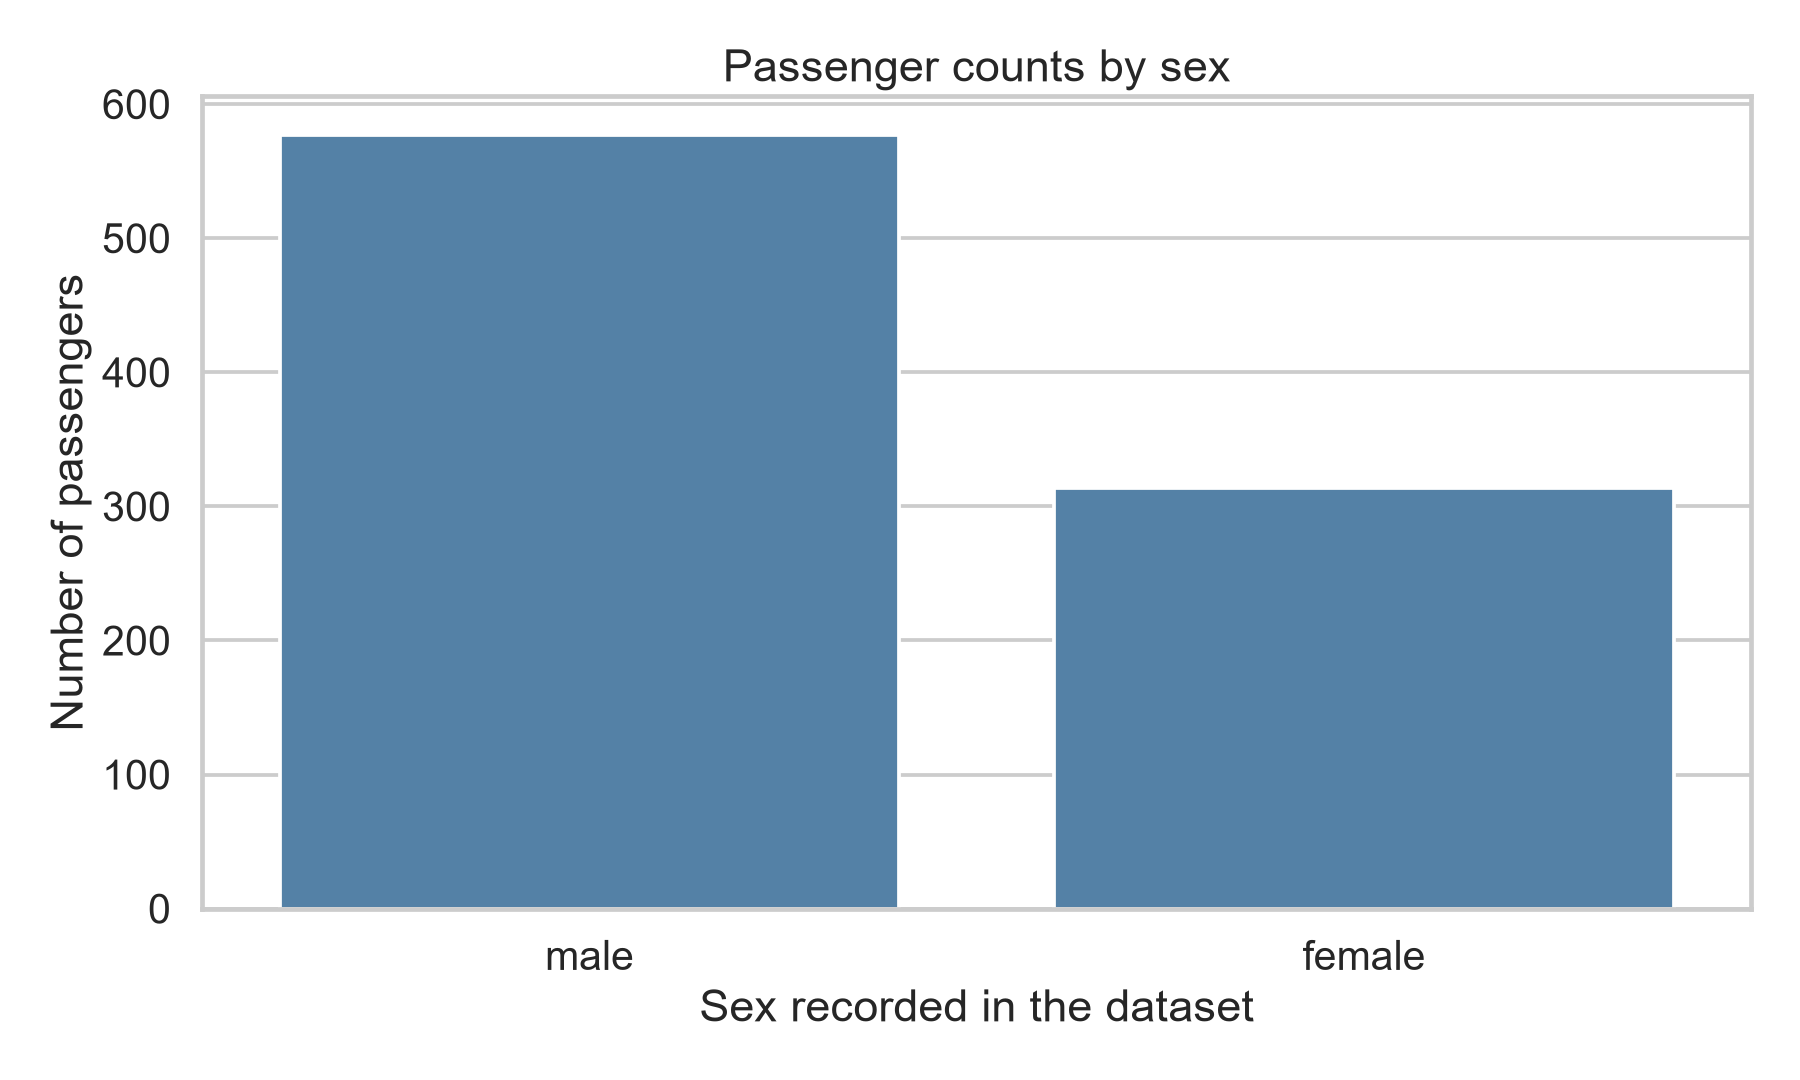

In [2]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="sex", color="steelblue")
plt.title("Passenger counts by sex")
plt.xlabel("Sex recorded in the dataset")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.show()


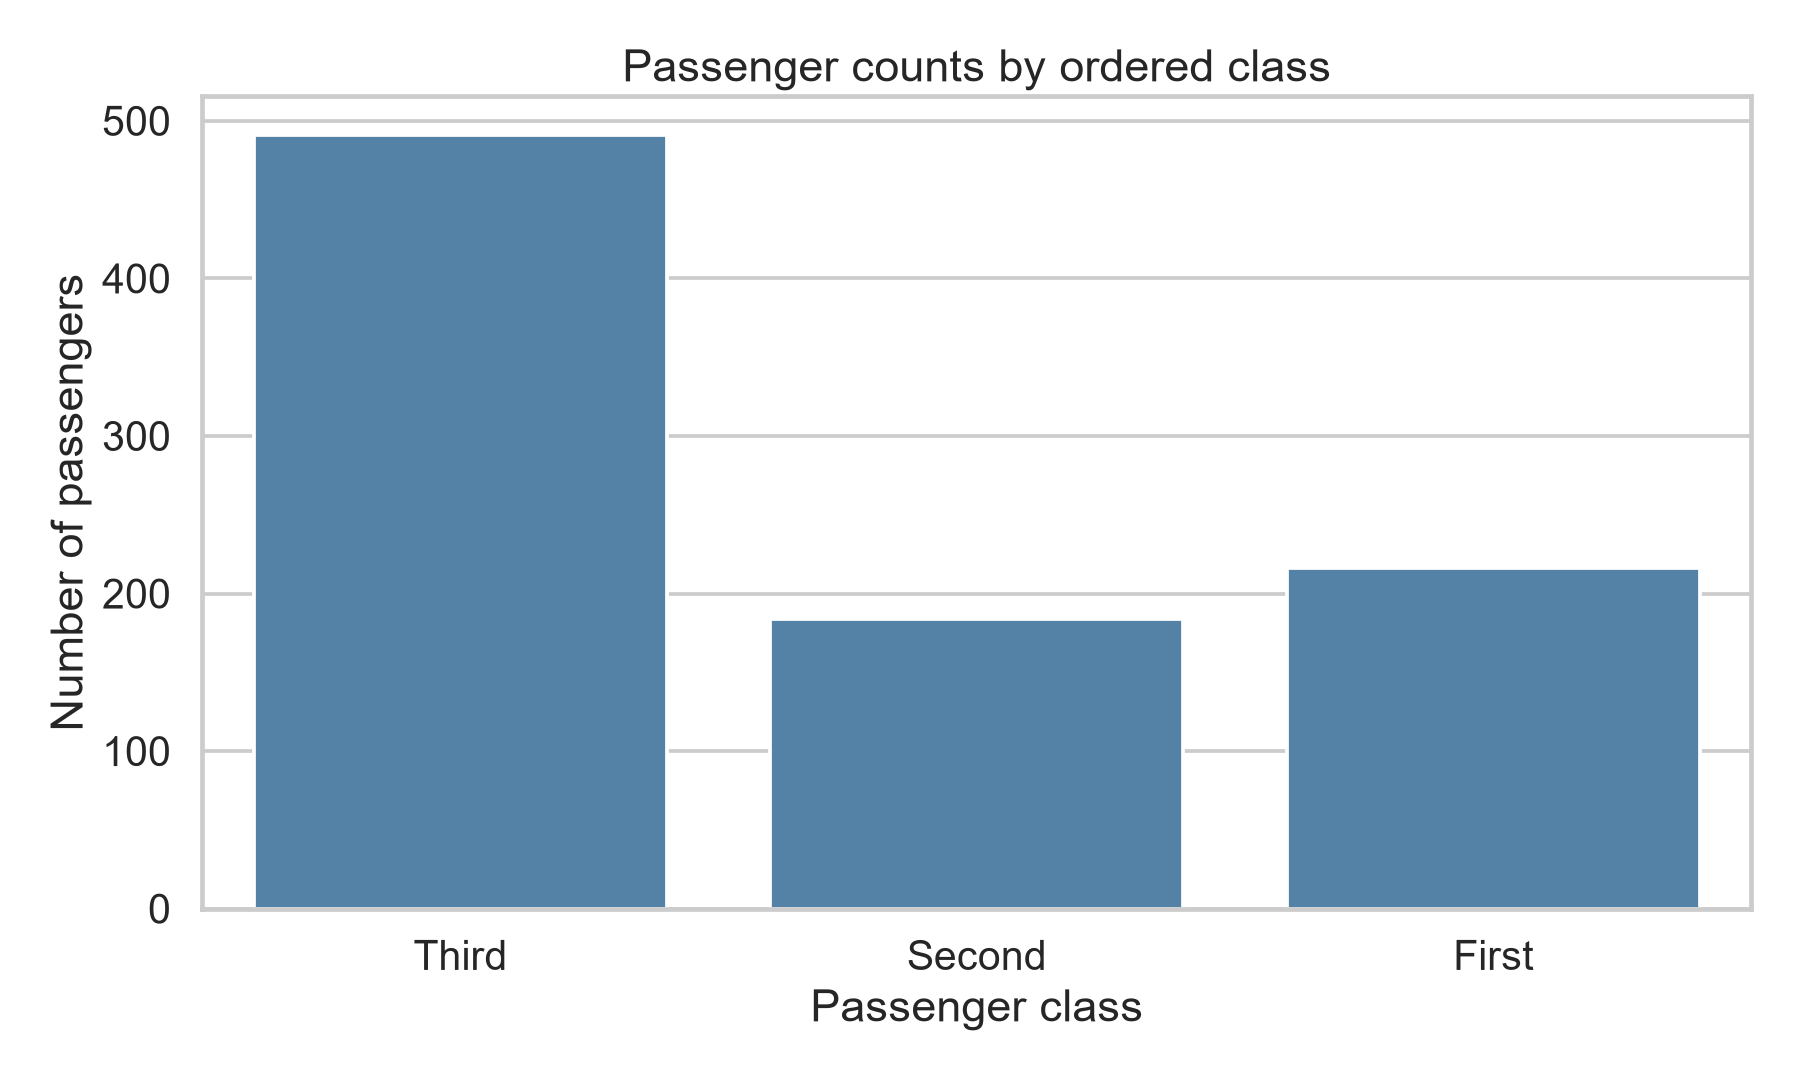

In [3]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="class", order=class_order, color="steelblue")
plt.title("Passenger counts by ordered class")
plt.xlabel("Passenger class")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.show()


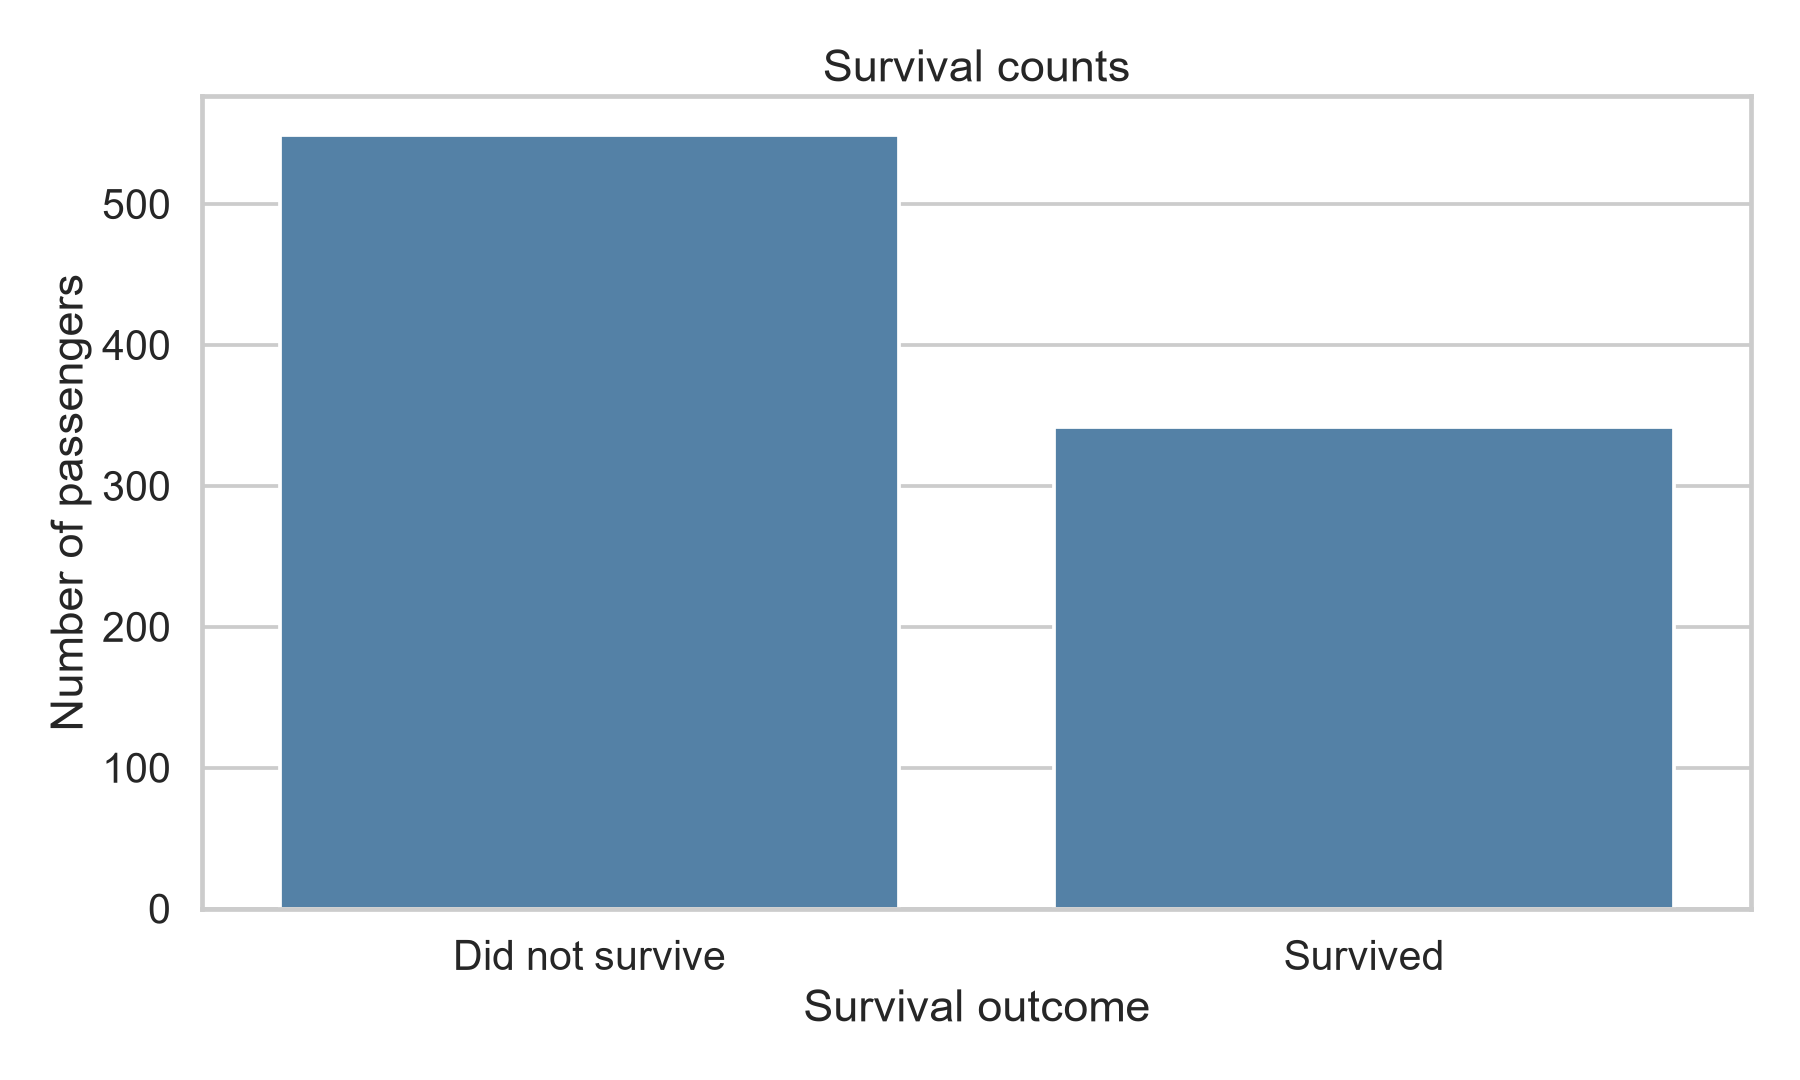

In [4]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="survival", order=["Did not survive", "Survived"], color="steelblue")
plt.title("Survival counts")
plt.xlabel("Survival outcome")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.show()


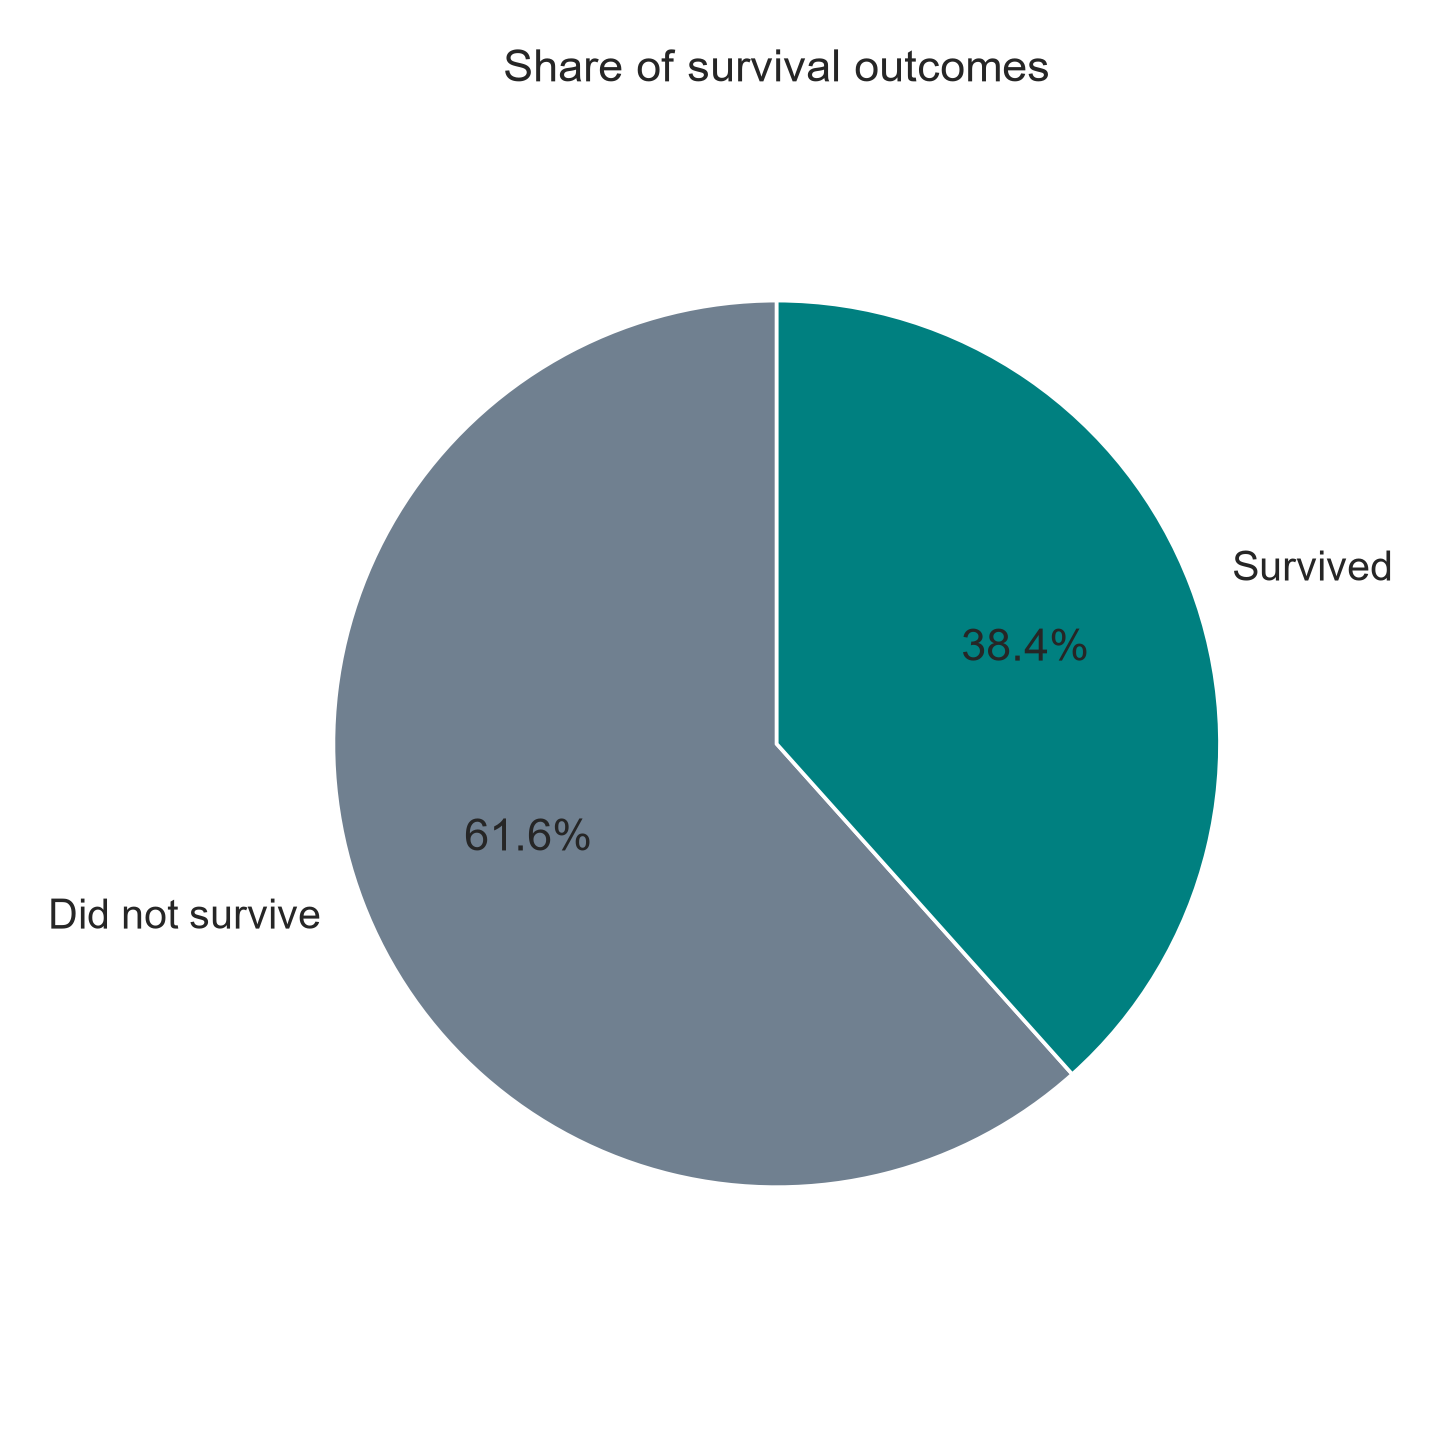

In [5]:
survival_counts = df["survival"].value_counts().reindex(["Did not survive", "Survived"])
plt.figure(figsize=(8, 8))
plt.pie(survival_counts, labels=survival_counts.index, autopct="%1.1f%%",
        startangle=90, colors=["slategray", "teal"],
        wedgeprops={"edgecolor": "white"})
plt.title("Share of survival outcomes")
plt.axis("equal")
plt.tight_layout()
plt.show()


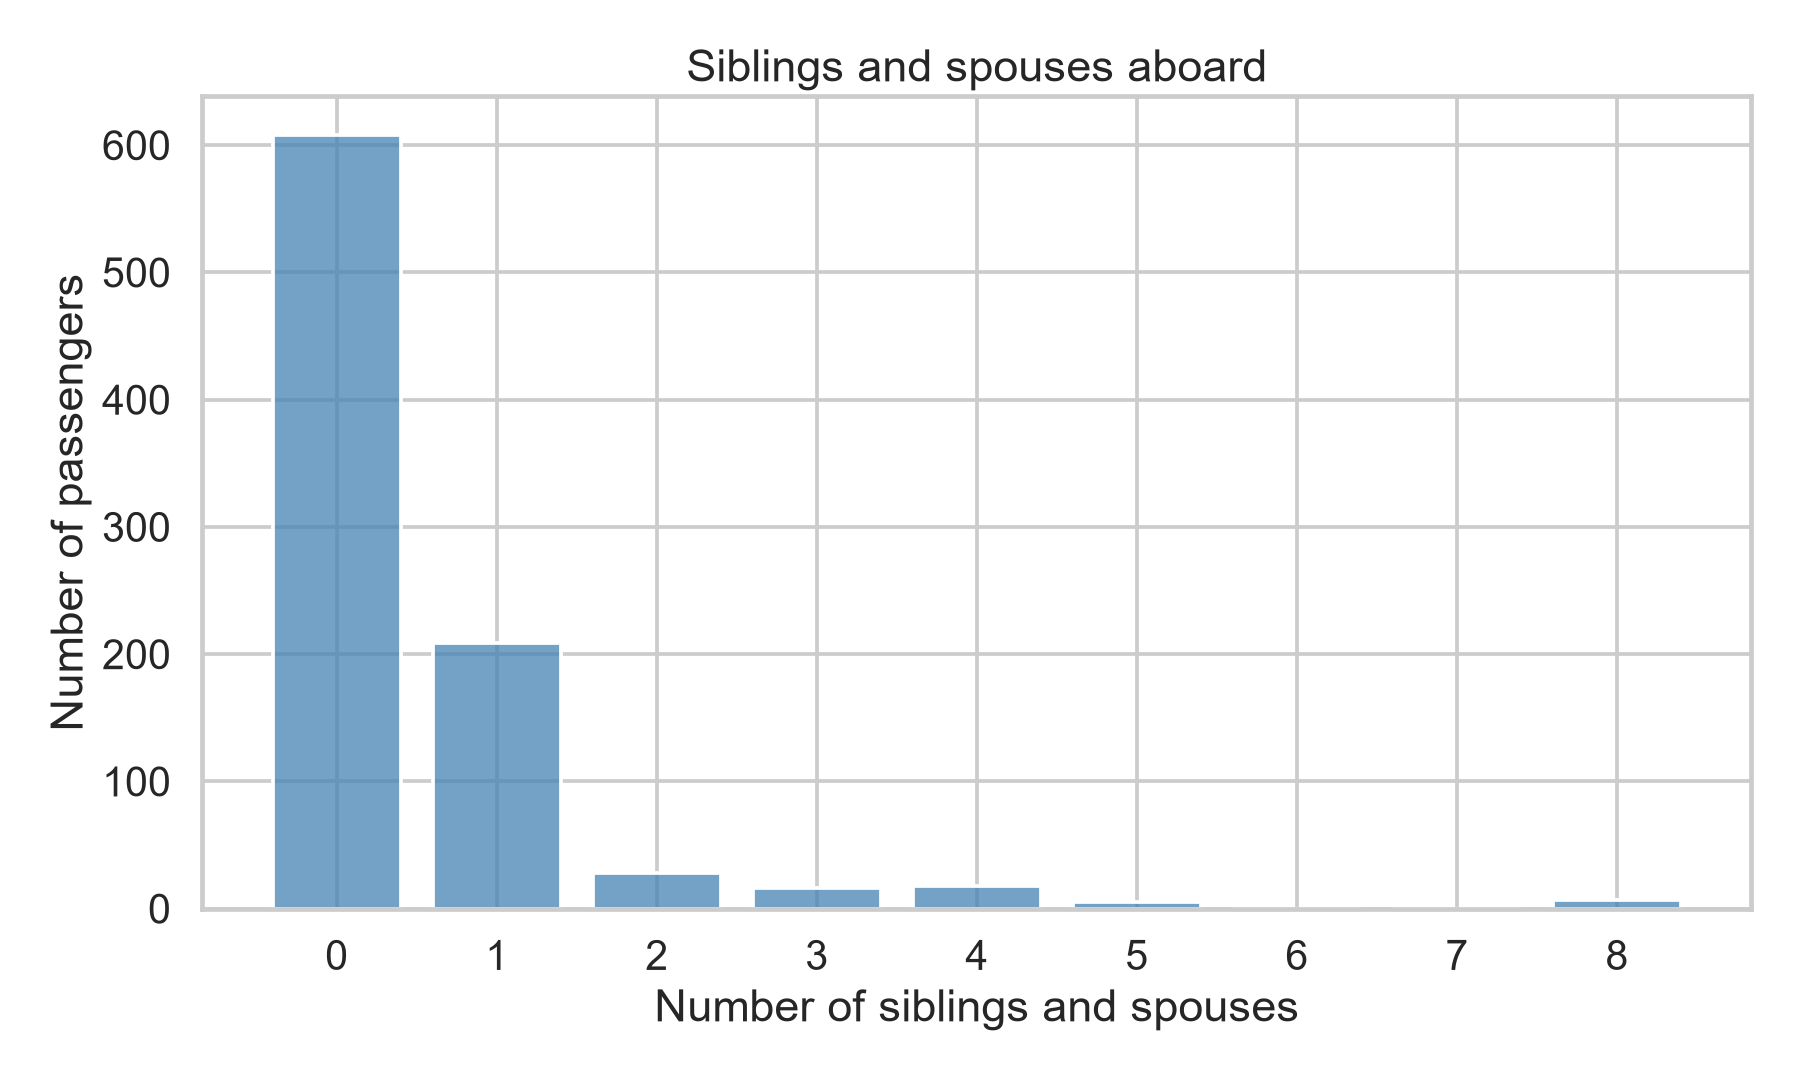

In [6]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="sibsp", discrete=True, shrink=0.8, color="steelblue")
plt.title("Siblings and spouses aboard")
plt.xlabel("Number of siblings and spouses")
plt.ylabel("Number of passengers")
plt.xticks(range(int(df["sibsp"].max()) + 1))
plt.tight_layout()
plt.show()


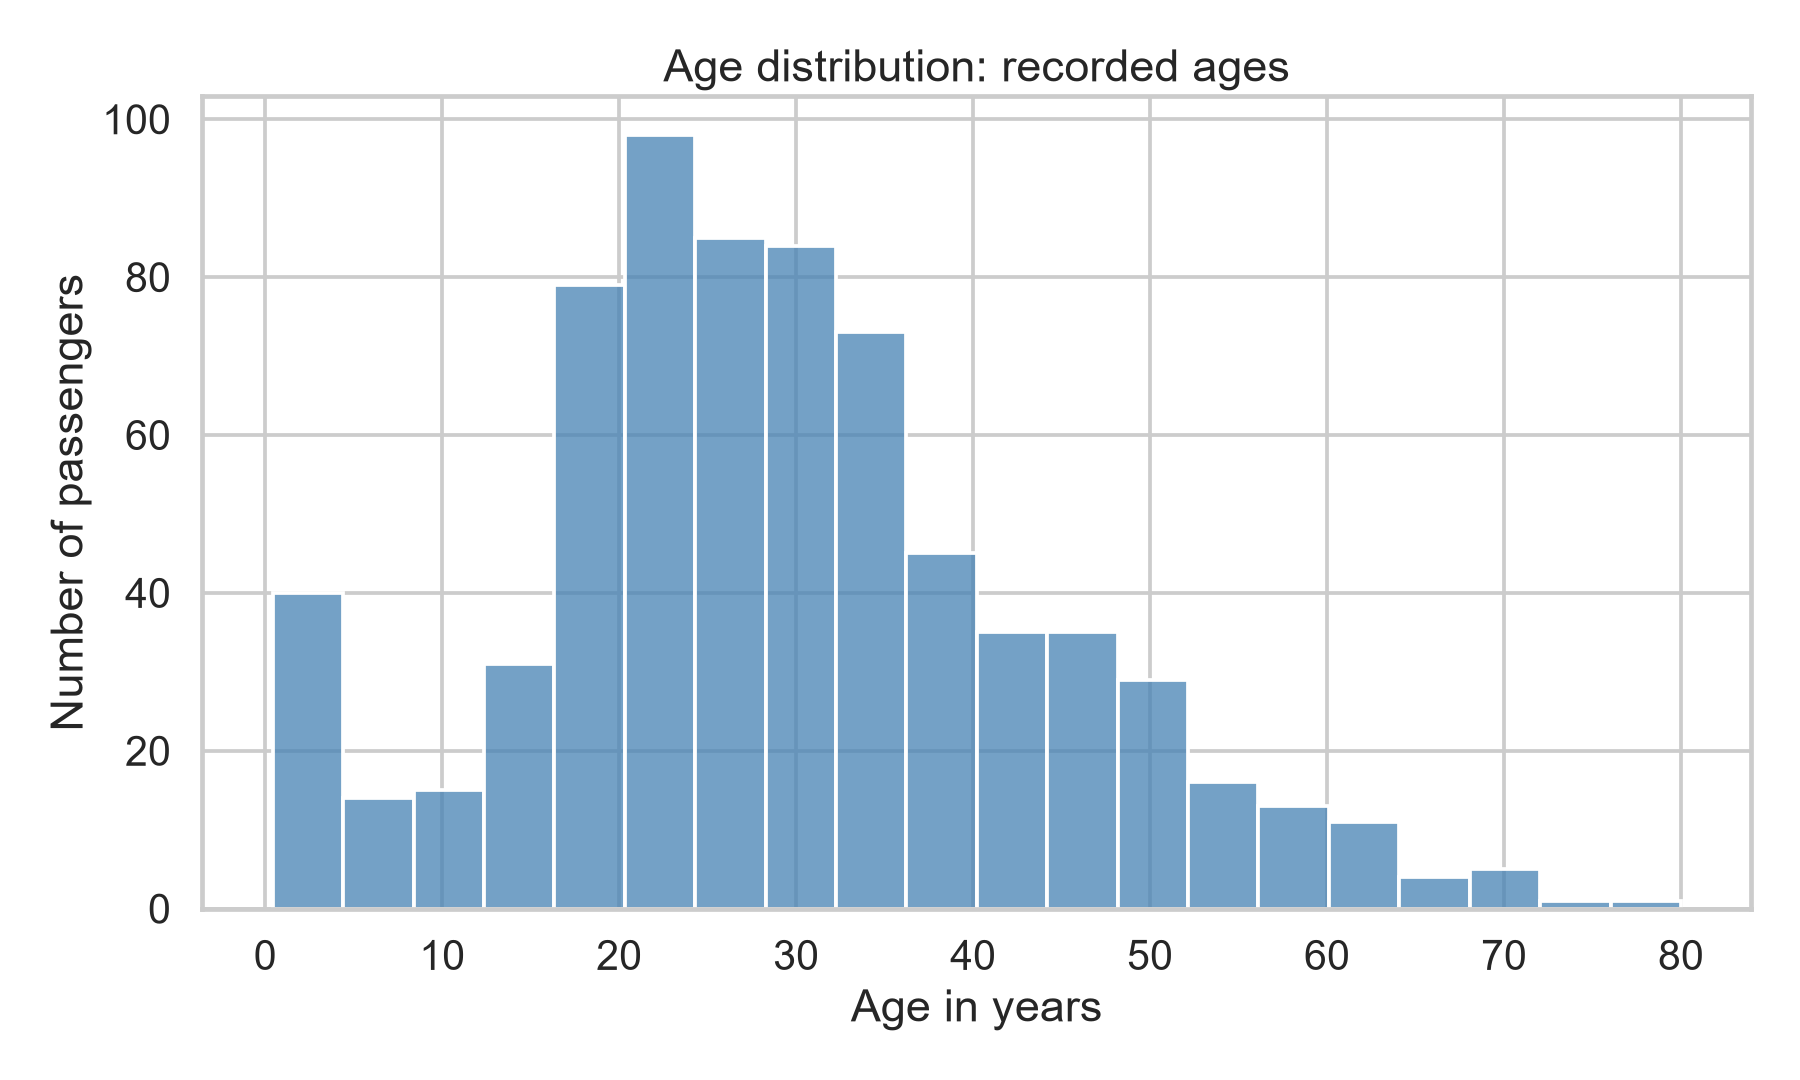

In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(data=age_data, x="age", bins=20, color="steelblue")
plt.title("Age distribution: recorded ages")
plt.xlabel("Age in years")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.show()


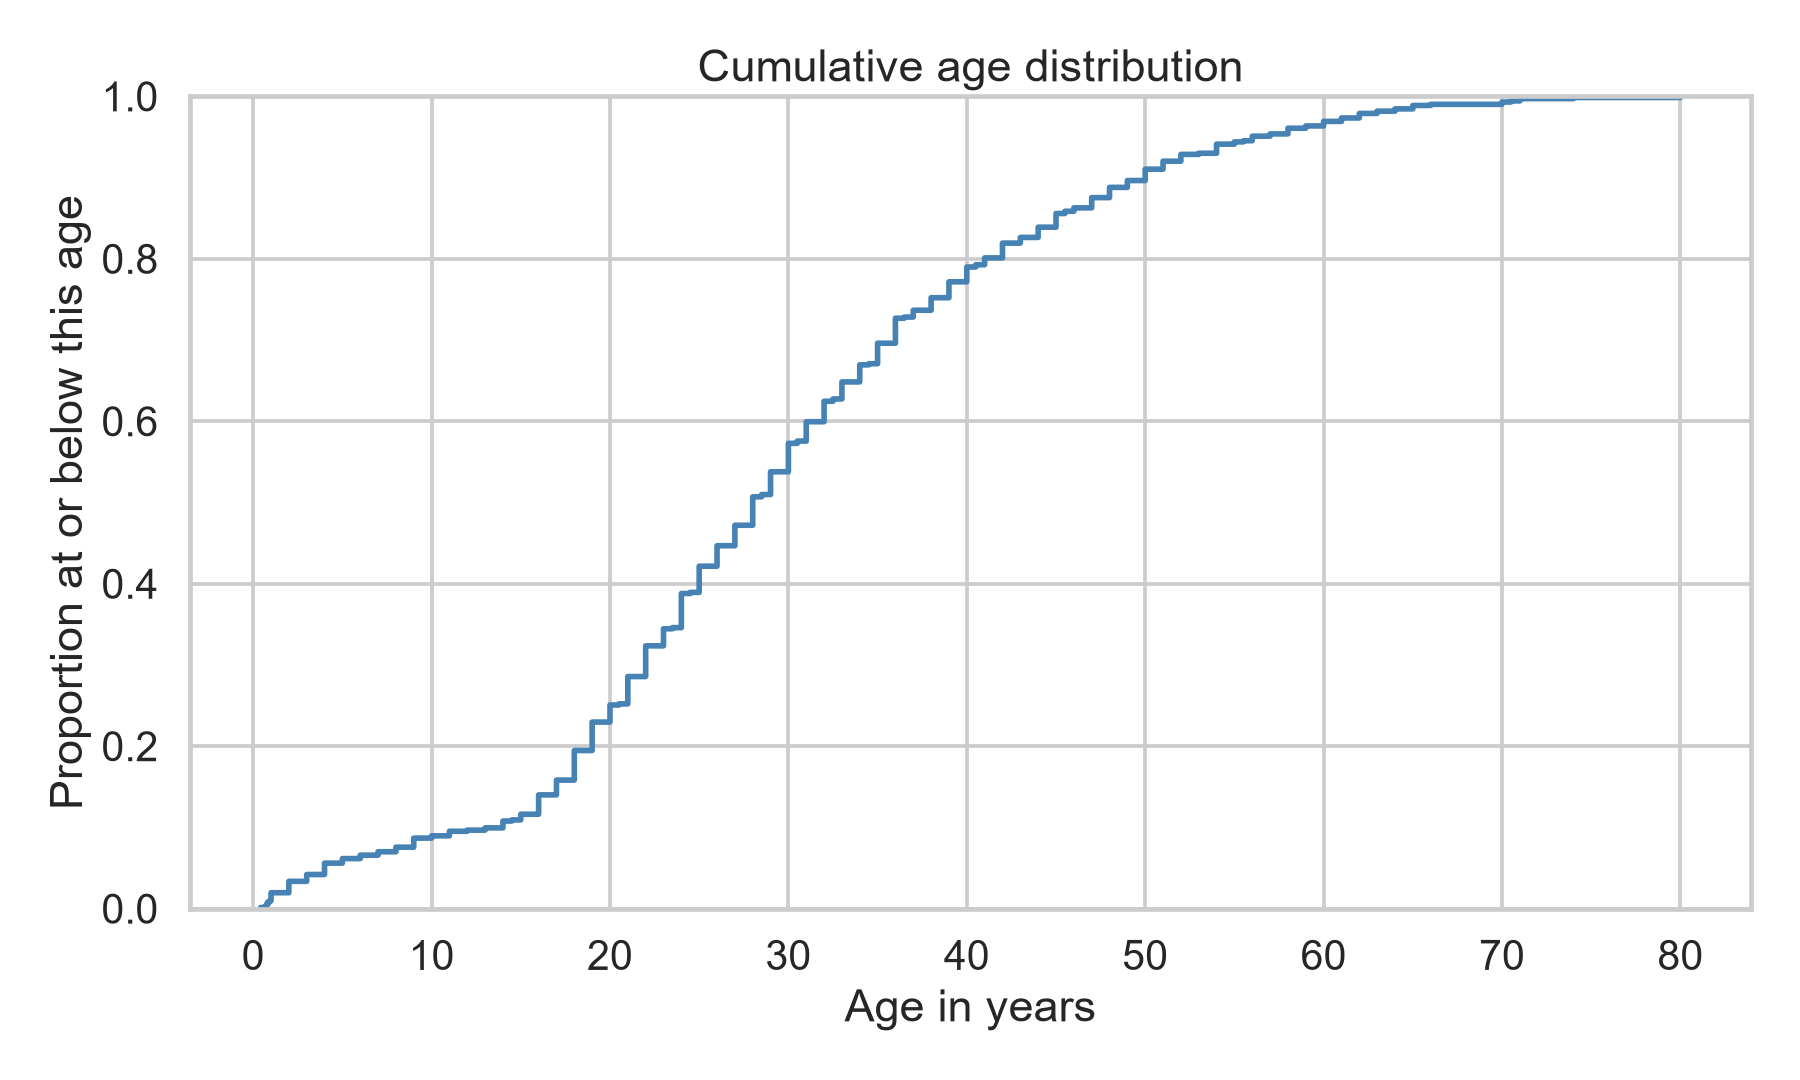

In [8]:
plt.figure(figsize=(10, 6))
sns.ecdfplot(data=age_data, x="age", color="steelblue")
plt.title("Cumulative age distribution")
plt.xlabel("Age in years")
plt.ylabel("Proportion at or below this age")
plt.tight_layout()
plt.show()


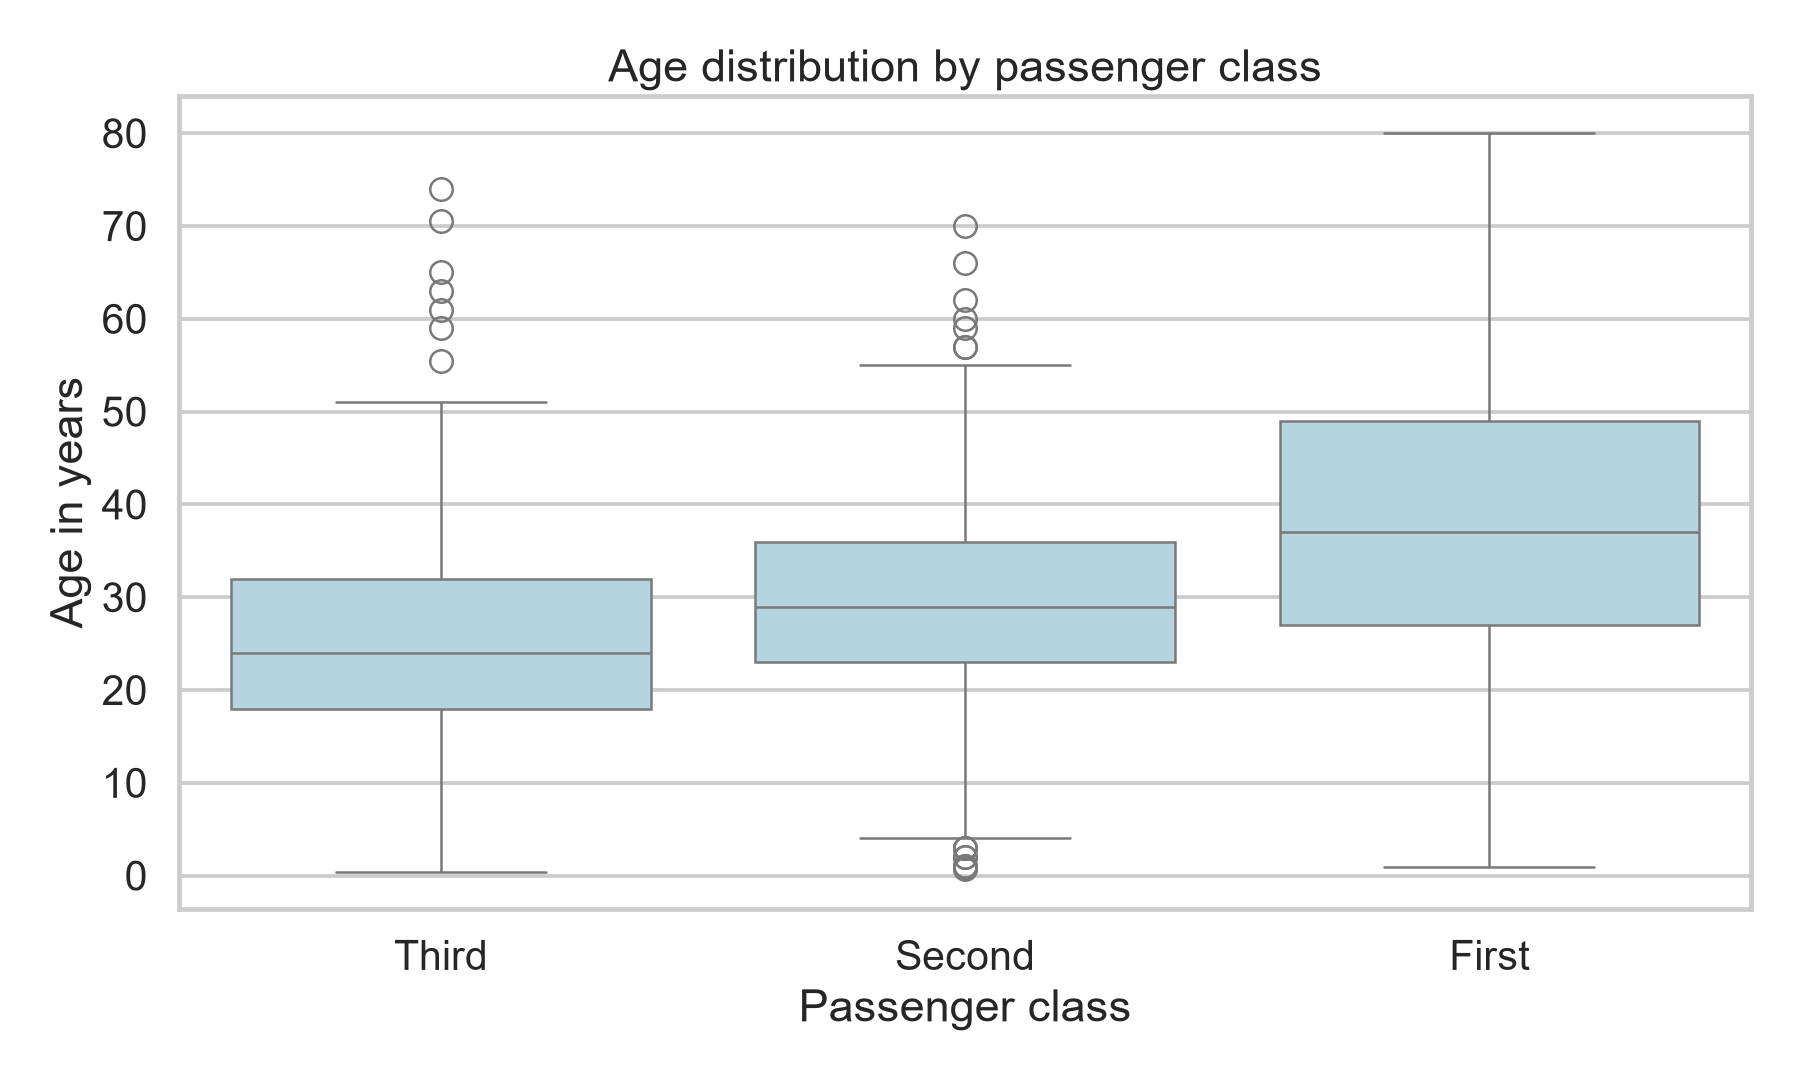

In [9]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=age_data, x="class", y="age", order=class_order, color="lightblue")
plt.title("Age distribution by passenger class")
plt.xlabel("Passenger class")
plt.ylabel("Age in years")
plt.tight_layout()
plt.show()


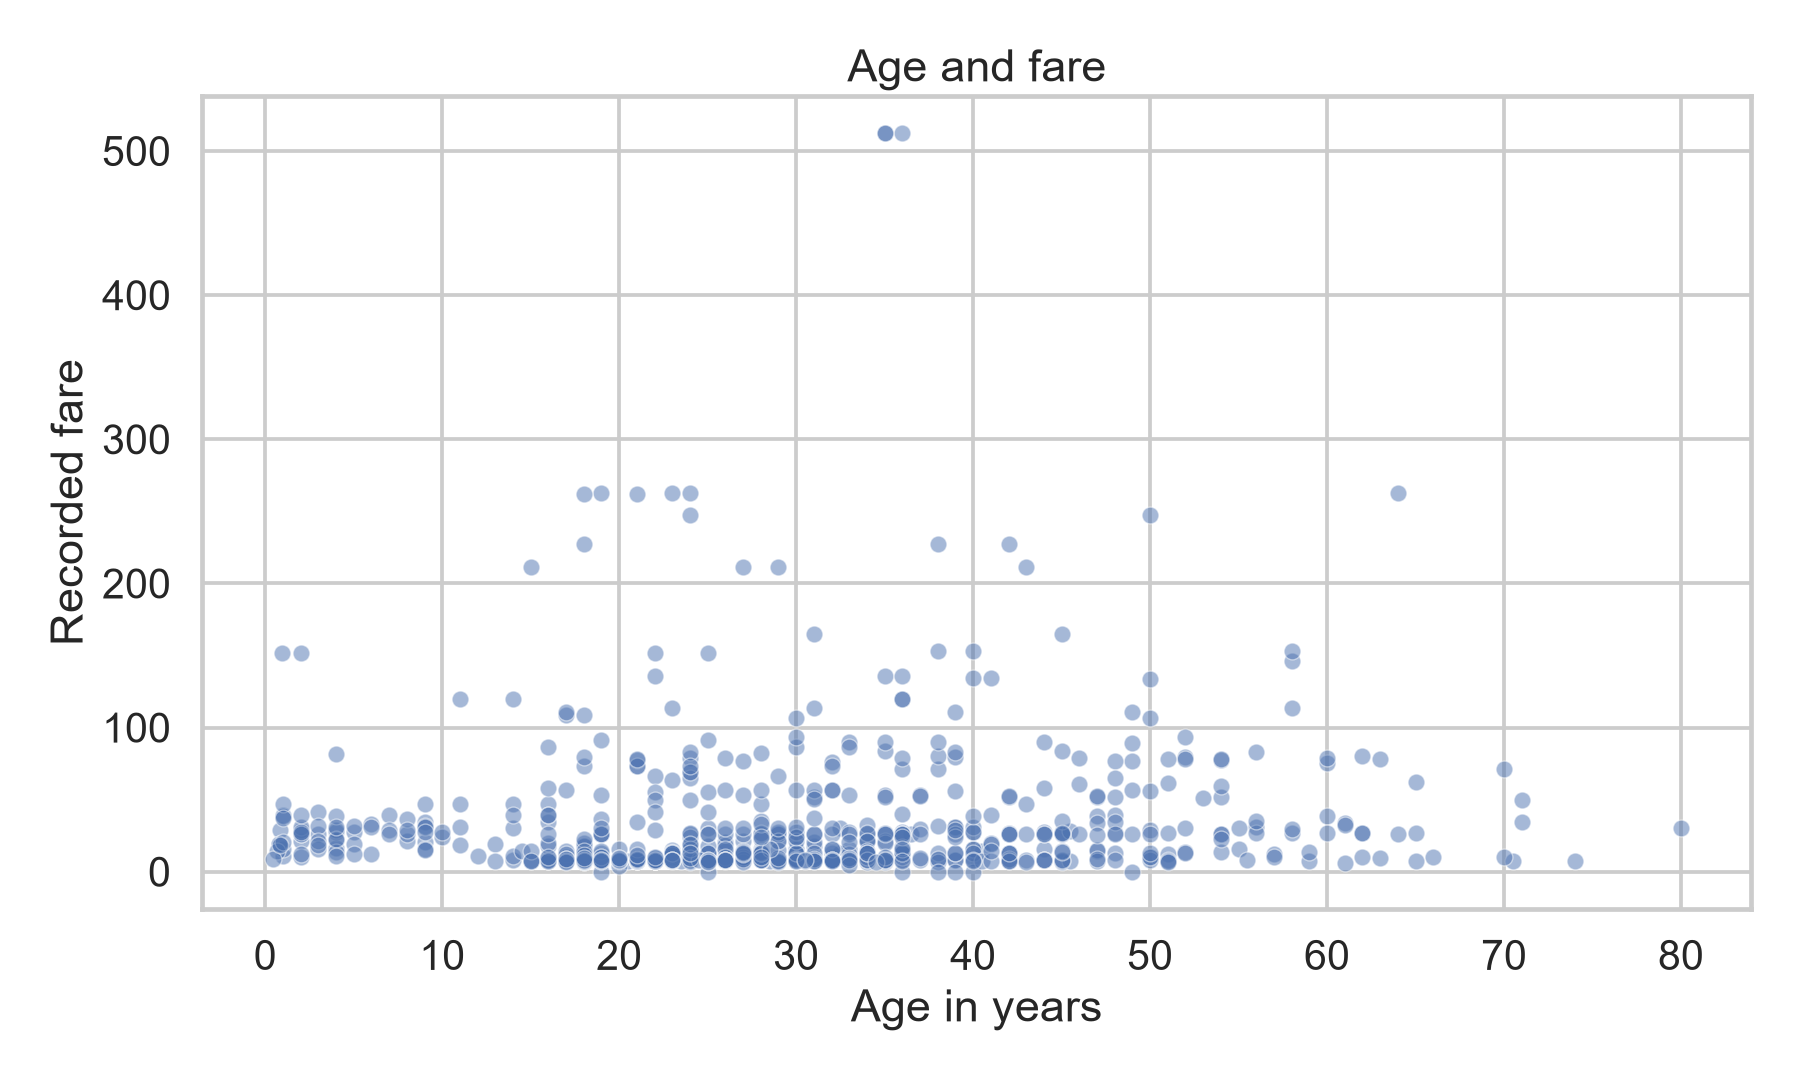

In [10]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=age_data, x="age", y="fare", alpha=0.5, s=45)
plt.title("Age and fare")
plt.xlabel("Age in years")
plt.ylabel("Recorded fare")
plt.tight_layout()
plt.show()


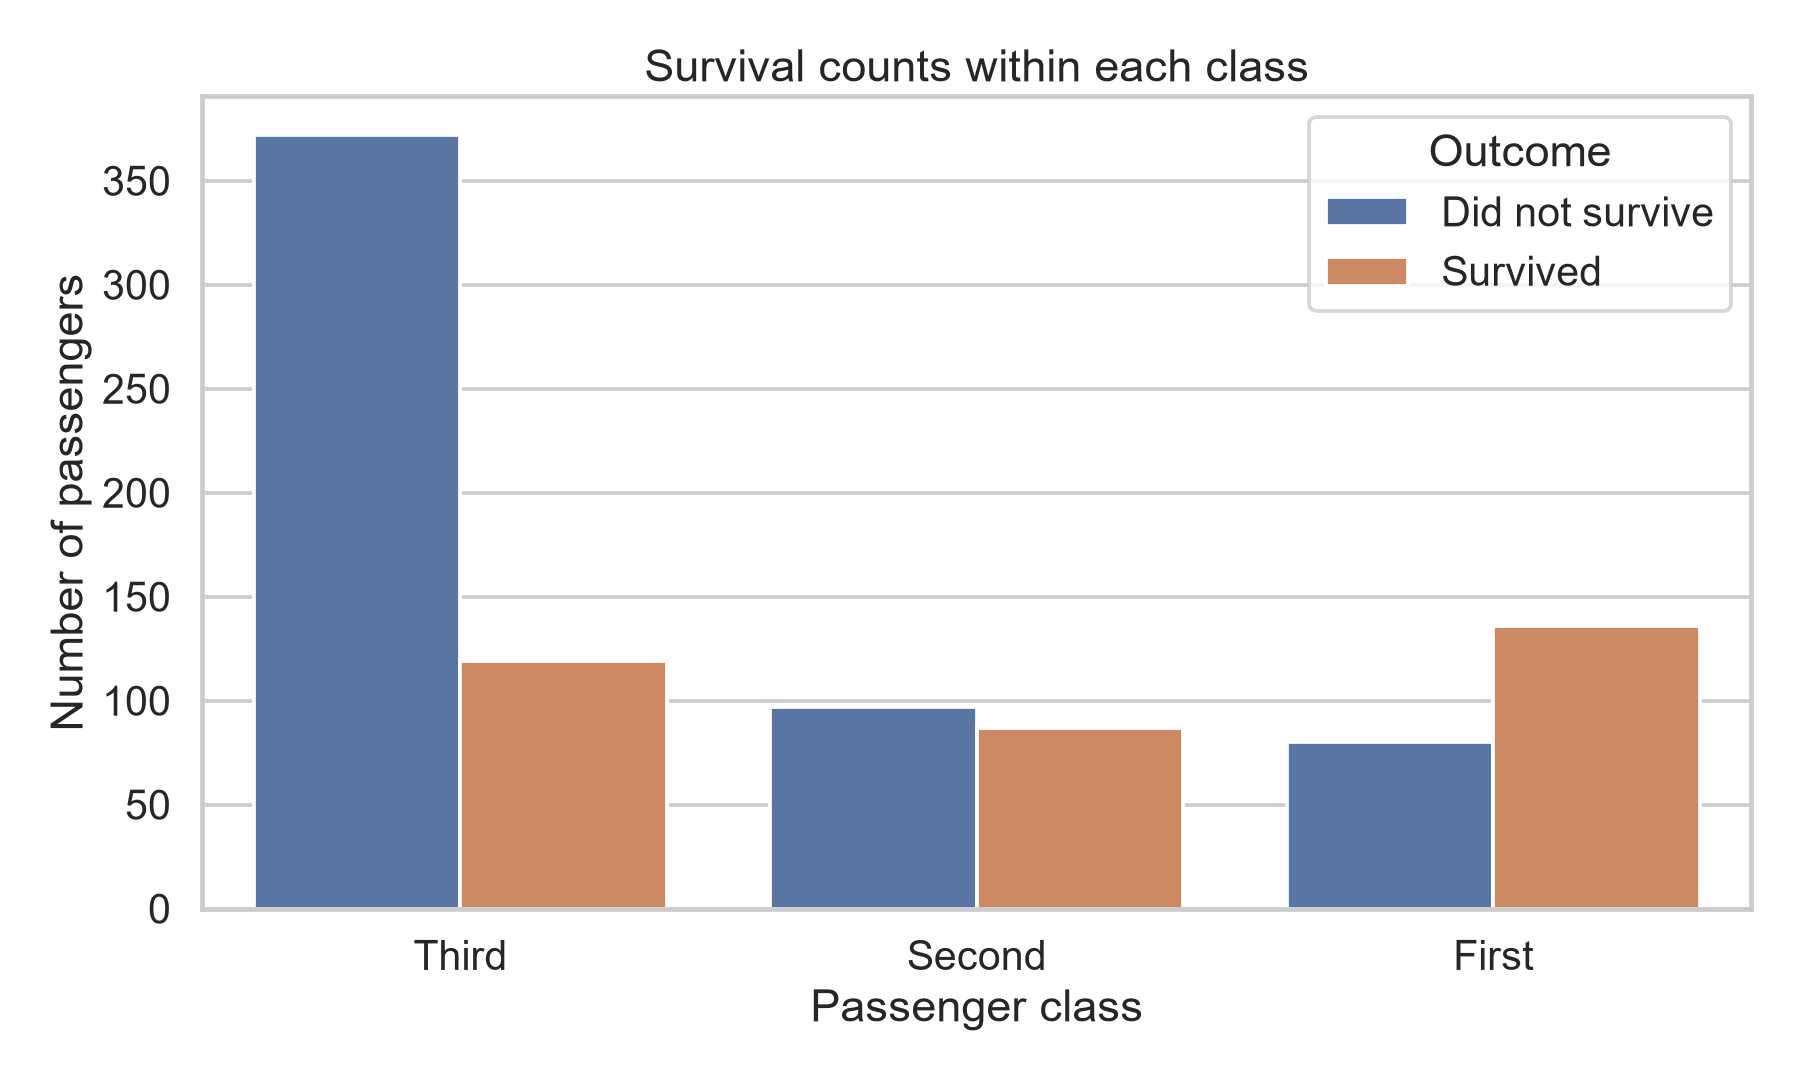

In [11]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="class", hue="survival", order=class_order,
              hue_order=["Did not survive", "Survived"])
plt.title("Survival counts within each class")
plt.xlabel("Passenger class")
plt.ylabel("Number of passengers")
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()


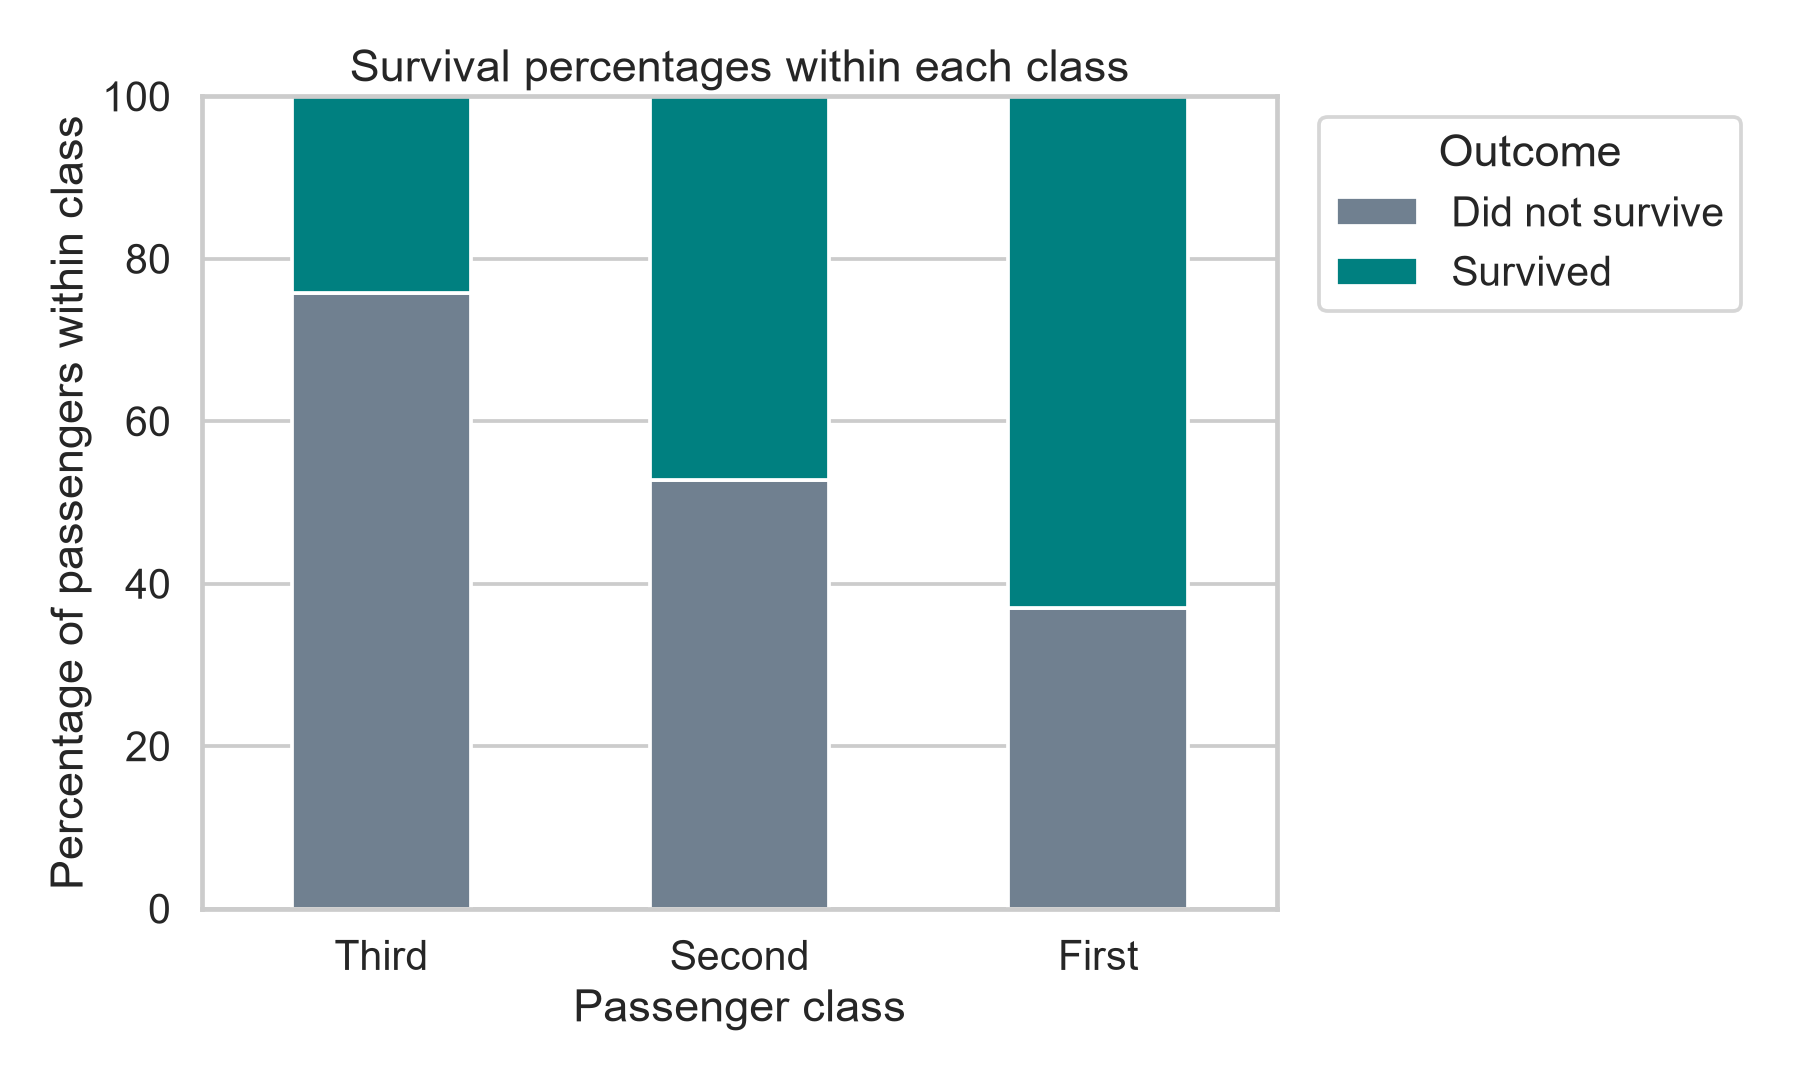

In [12]:
survival_percent = pd.crosstab(df["class"], df["survival"], normalize="index").mul(100)
survival_percent = survival_percent.reindex(class_order)[["Did not survive", "Survived"]]
print(survival_percent.round(1))
survival_percent.plot(kind="bar", stacked=True, figsize=(10, 6), color=["slategray", "teal"])
plt.title("Survival percentages within each class")
plt.xlabel("Passenger class")
plt.ylabel("Percentage of passengers within class")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


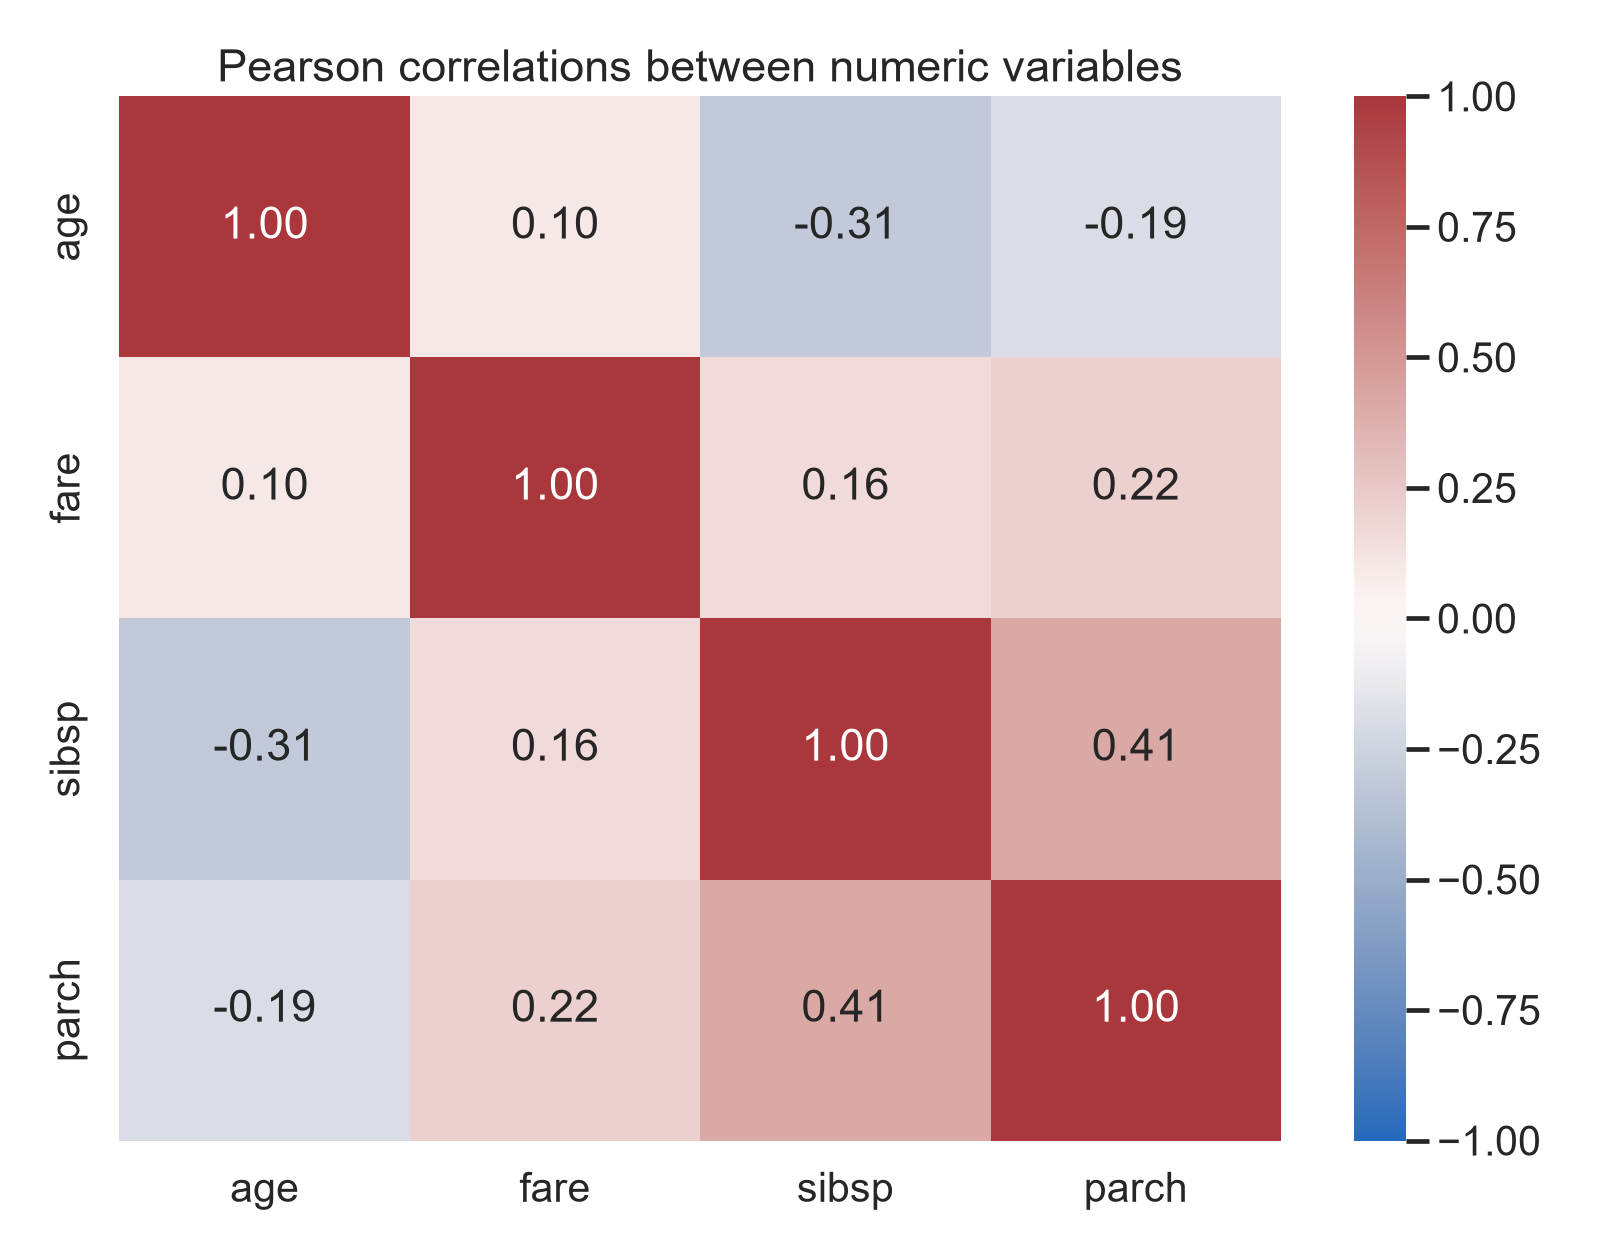

In [13]:
numeric_columns = ["age", "fare", "sibsp", "parch"]
correlation = df[numeric_columns].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0)
plt.title("Pearson correlations between numeric variables")
plt.tight_layout()
plt.show()
